# Schritt 2: Feature Engineering

**Ziel dieses Notebooks:** aus den beiden Rohdateien eine Modelltabelle bauen, mit einer Zeile pro Vertrag, den
Zielgrößen und den Merkmalen in der Form, die die Modelle in Schritt 3 brauchen. Alle Entscheidungen aus Schritt 1
werden hier an einer Stelle angewendet, sodass dieses Notebook die Tabelle von den Rohdaten an selbst erzeugt.

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 200)   # show wide tables without cutting columns

## 1. Rohdaten laden und die Entscheidungen aus Schritt 1 anwenden

In [2]:
# load the raw data (download it first with: python get_data.py)
freq_raw = pd.read_parquet("../data/freMTPL2freq.parquet")
sev_raw = pd.read_parquet("../data/freMTPL2sev.parquet")
f = freq_raw.copy()
t = sev_raw.copy()

# types (step 1, section 2)
int_cols = ["IDpol", "ClaimNb", "VehPower", "VehAge", "DrivAge", "BonusMalus", "Density"]
f[int_cols] = f[int_cols].astype("int64")
t["IDpol"] = t["IDpol"].astype("int64")
for col in ["Area", "VehBrand", "VehGas", "Region"]:
    f[col] = f[col].astype(str)

# claims without a contract are dropped (section 3)
t = t[t["IDpol"].isin(f["IDpol"])].copy()

# exposure above one year is capped (section 7)
f["Exposure"] = f["Exposure"].clip(upper=1)

In [3]:
# one row per contract (section 4); the claim count is the number of claims with an amount (section 5)
claims = t.groupby("IDpol")["ClaimAmount"].agg(["count", "sum"]).reset_index()
claims.columns = ["IDpol", "claim_rows", "ClaimAmount"]

df = f.merge(claims, on="IDpol", how="left")
df["claim_rows"] = df["claim_rows"].fillna(0).astype(int)
df["ClaimAmount"] = df["ClaimAmount"].fillna(0)
df = df.drop(columns=["ClaimNb"])   # the declared count is not used (section 5)

# the portfolio must be exactly the one of step 1
E = df["Exposure"].sum()
N = df["claim_rows"].sum()
S = df["ClaimAmount"].sum()
print("contracts:", len(df), "| contract-years:", round(E), "| claims:", N, "| total claim amount:", round(S))
print("frequency:", round(N / E, 4), "| severity:", round(S / N, 2), "| pure premium:", round(S / E, 2))
assert len(df) == 678013 and N == 26444 and round(S / E, 2) == 167.18

contracts: 678013 | contract-years: 358360 | claims: 26444 | total claim amount: 59909216
frequency: 0.0738 | severity: 2265.51 | pure premium: 167.18


**Findings**

The table has one row per contract and exactly the portfolio of step 1: 678,013 contracts, 358,360 contract-years,
26,444 claims, total claim amount 59,909,216, frequency 0.0738, severity 2,265.51, **pure premium 167.18**. The
`assert` stops the notebook if the number of contracts, the number of claims or the pure premium differ from step 1.
The declared `ClaimNb` is removed, so it cannot be used by mistake later.

## 2. Großschäden kappen

In [4]:
# how much of the total cost lies above a cap?
ca = t["ClaimAmount"]
for cap in [50000, 100000, 200000]:
    above = (ca - ca.clip(upper=cap)).sum()
    print("cap", cap, "| claims above:", (ca > cap).sum(), "| share of the total cost above the cap:", round(above / ca.sum(), 3))

cap 50000 | claims above: 88 | share of the total cost above the cap: 0.226
cap 100000 | claims above: 41 | share of the total cost above the cap: 0.177
cap 200000 | claims above: 20 | share of the total cost above the cap: 0.129


In [5]:
# cap every single claim at 100,000, then sum per contract
CAP = 100000
t["ClaimAmountCapped"] = t["ClaimAmount"].clip(upper=CAP)
df["ClaimAmountCapped"] = df["IDpol"].map(t.groupby("IDpol")["ClaimAmountCapped"].sum()).fillna(0)

print("contracts with a claim above the cap:", (df["ClaimAmount"] > df["ClaimAmountCapped"]).sum())
print("total cost / capped cost:", round(df["ClaimAmount"].sum() / df["ClaimAmountCapped"].sum(), 3))

contracts with a claim above the cap: 41
total cost / capped cost: 1.215


**Findings**

Step 1 showed that a few large claims dominate the cost: the largest claim alone is 6.8 % of the total, and one claim
made the Bonus-Malus band (90, 100] look more expensive than the worst band. A model fitted on such amounts would give a
whole group of customers a higher premium because of a single claim.

* 41 claims, each in a different contract, are above 100,000. The parts of these claims above the cap are 17.7 % of
  the total cost.
* A cap at 50,000 would move 22.6 % of the cost (88 claims) into a flat loading; a cap at 200,000 would still leave
  single claims of up to 200,000 in the data (20 claims above it).

**Decision:** every single claim is capped at 100,000 before fitting (`ClaimAmountCapped`). The models learn the
differences between customers from the capped amounts. The cost above the cap is added back in step 4 as one uniform
factor for all customers (on all data: total cost / capped cost = 1.215; step 4 uses the value of the training part
only). The cap is a judgment call; testing other caps is an improvement idea in step 4.

## 3. Zielgrößen: Schadenhäufigkeit, Schadenhöhe und Schadenbedarf

In [6]:
# targets per contract
df["Frequency"] = df["claim_rows"] / df["Exposure"]                  # claims per year
df["Severity"] = df["ClaimAmountCapped"] / df["claim_rows"]          # average capped claim (NaN without a claim)
df["PurePremium"] = df["ClaimAmount"] / df["Exposure"]               # the target: cost per contract-year
df["PurePremiumCapped"] = df["ClaimAmountCapped"] / df["Exposure"]   # the same with capped claims, used for fitting
df["has_claim"] = df["claim_rows"] > 0

# check: cost per year = claims per year x cost per claim
c = df["has_claim"]
assert np.allclose(df.loc[c, "PurePremiumCapped"], df.loc[c, "Frequency"] * df.loc[c, "Severity"])

print("frequency:", round(np.average(df["Frequency"], weights=df["Exposure"]), 4))
print("severity (capped):", round(df["ClaimAmountCapped"].sum() / df["claim_rows"].sum(), 2))
print("pure premium:", round(np.average(df["PurePremium"], weights=df["Exposure"]), 2),
      "| capped:", round(np.average(df["PurePremiumCapped"], weights=df["Exposure"]), 2))

frequency: 0.0738
severity (capped): 1864.4
pure premium: 167.18 | capped: 137.58


**Findings**

The target is `ClaimAmount / Exposure`, the cost per contract-year (`PurePremium`, on average
167.18). It is the product of two parts:

**cost per year = claims per year (`Frequency`, 0.0738) × cost per claim (`Severity`, capped: 1,864.40)**

The `assert` checks this identity for every contract with a claim. With capped claims the cost per year is 137.58 on
average (`PurePremiumCapped`).

**Decision:** step 3 models the two parts separately: the frequency with a Poisson model and the severity with a Gamma
model; the premium is their product. Reasons: step 1 showed that the features act mainly on the frequency, and the two
parts have different distributions (claim counts against positive amounts). `Exposure` is the weight of every
contract: a contract observed for 0.1 years counts 0.1.

## 4. Merkmale für die Modelle

In [7]:
# bands for the GLM (DrivAge and BonusMalus as in step 1, section 11)
df["DrivAgeBand"] = pd.cut(df["DrivAge"], [17, 20, 24, 29, 39, 49, 59, 69, 120],
                           labels=["18-20", "21-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70+"])
df["BonusMalusBand"] = pd.cut(df["BonusMalus"], [49, 50, 60, 70, 80, 90, 100, 300],
                              labels=["50", "51-60", "61-70", "71-80", "81-90", "91-100", "101+"])
df["VehAgeBand"] = pd.cut(df["VehAge"], [-1, 4, 9, 14, 19, 200], labels=["0-4", "5-9", "10-14", "15-19", "20+"])
df["VehPowerBand"] = pd.cut(df["VehPower"], [3, 5, 7, 9, 11, 15], labels=["4-5", "6-7", "8-9", "10-11", "12+"])
for col in ["Area", "Region", "VehBrand", "VehGas"]:
    df[col] = df[col].astype("category")

bands = ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "VehPowerBand"]
assert df[bands].notna().all().all()          # every contract falls into a band

# enough claims in every band?
for col in bands:
    g = df.groupby(col, observed=True)[["Exposure", "claim_rows"]].sum()
    g["frequency"] = g["claim_rows"] / g["Exposure"]
    print(g.round(3), "\n")

              Exposure  claim_rows  frequency
DrivAgeBand                                  
18-20         2584.543         617      0.239
21-24         9904.348        1394      0.141
25-29        25775.651        2245      0.087
30-39        82320.268        5725      0.070
40-49        87645.366        6566      0.075
50-59        79880.858        5623      0.070
60-69        40077.472        2470      0.062
70+          30171.599        1804      0.060 



                  Exposure  claim_rows  frequency
BonusMalusBand                                   
50              225152.651       11592      0.051
51-60            47958.467        3576      0.075
61-70            26484.083        3116      0.118
71-80            26555.703        2798      0.105
81-90            15243.429        1720      0.113
91-100           13395.042        2386      0.178
101+              3570.729        1256      0.352 

              Exposure  claim_rows  frequency
VehAgeBand                                   
0-4         128965.004        9413      0.073
5-9         100225.808        8044      0.080
10-14        86058.994        6495      0.075
15-19        35966.514        2173      0.060
20+           7143.786         319      0.045 



                Exposure  claim_rows  frequency
VehPowerBand                                   
4-5           128203.456        9118      0.071
6-7           160417.337       11898      0.074
8-9            38012.610        2865      0.075
10-11          23858.399        1931      0.081
12+             7868.303         632      0.080 



**Findings**

The GLM in step 3 is a multiplicative tariff: base premium × factor of the Bonus-Malus band × factor of the age band
× ... A numeric feature whose effect is not a straight line (for example the age, step 1) therefore gets bands, with one
factor per band. The gradient boosting model gets the raw numbers instead and finds the cut points itself.

* `DrivAgeBand` and `BonusMalusBand` use the bands of step 1. Their smallest bands are 18–20 (617 claims) and 101+
  (1,256 claims).
* `VehAgeBand` in steps of five years: the frequency is 0.073–0.080 up to 14 years and then falls to 0.060 (15–19) and
  0.045 (20+, 319 claims). The open last band also takes the placeholder values 99 and 100 from step 1.
* `VehPowerBand` in steps of two, 12 and more together (632 claims): the frequency rises only a little, from 0.071 to
  0.080–0.081.
* The `assert` confirms that every contract falls into a band.

                  Exposure  claim_rows  frequency
log(Density)                                     
(-0.0102, 1.02]     51.810           3      0.058
(1.02, 2.041]     1575.211          80      0.051
(2.041, 3.061]   20991.424        1021      0.049
(3.061, 4.081]   51428.638        2945      0.057
(4.081, 5.102]   63048.062        4052      0.064
(5.102, 6.122]   65005.854        4454      0.069
(6.122, 7.143]   55092.972        4470      0.081
(7.143, 8.163]   55832.291        5019      0.090
(8.163, 9.183]   36897.843        3606      0.098
(9.183, 10.204]   8436.000         794      0.094


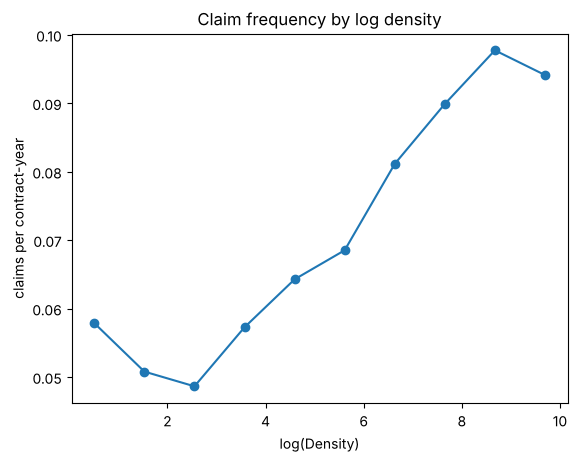

In [8]:
# claim frequency against log density (10 intervals of equal width)
log_density = np.log(df["Density"]).rename("log(Density)")
g = df.groupby(pd.cut(log_density, 10), observed=True)[["Exposure", "claim_rows"]].sum()
g["frequency"] = g["claim_rows"] / g["Exposure"]
print(g.round(3))

plt.plot([interval.mid for interval in g.index], g["frequency"], marker="o")
plt.xlabel("log(Density)")
plt.ylabel("claims per contract-year")
plt.title("Claim frequency by log density")
plt.show()

**Findings**

`Density` ranges from 1 to 27,000 (step 1). On the log scale the claim frequency rises steadily from 0.049 to 0.098
between log density 2 and 9.2, but in the highest interval (the most urban contracts) it falls back to 0.094. A
straight line in log density would therefore overprice the most urban contracts.

**Decision:** the GLM uses `Area` instead, the banding of `Density` that is already in the data (step 1, section 12:
A = 1–50 up to F = 10,008–27,000 inhabitants per km²), with one factor per area, the same approach as for the other
numeric features. `Density` itself is not used in the GLM. The gradient boosting model uses the raw `Density` (and not
`Area`), because it finds its own cut points.

In [9]:
# the categorical features: number of levels and the smallest level
for col in ["Area", "Region", "VehBrand", "VehGas"]:
    g = df.groupby(col, observed=True)["claim_rows"].sum()
    print(col, "| levels:", len(g), "| smallest level:", g.idxmin(), "with", g.min(), "claims")

Area | levels: 6 | smallest level: F with 774 claims
Region | levels: 22 | smallest level: R43 with 38 claims
VehBrand | levels: 11 | smallest level: B14 with 131 claims
VehGas | levels: 2 | smallest level: Regular with 12994 claims


**Findings**

`Area` (6 levels), `Region` (22), `VehBrand` (11) and `VehGas` (2) are categories:
one factor per level in the GLM, categorical splits in the gradient boosting model (which uses all of them except
`Area`). The smallest level is region R43 with 38 claims, so its factor will be uncertain (shrinking such factors
towards the average is an improvement idea in step 4). The smallest area, F, has 774 claims.

## 5. Hängt die Schadenhöhe von den Merkmalen ab?

In [10]:
# average capped claim per band (contracts with a claim only)
for col in ["DrivAgeBand", "BonusMalusBand"]:
    g = df[df["has_claim"]].groupby(col, observed=True)[["claim_rows", "ClaimAmountCapped"]].sum()
    g["average_claim"] = g["ClaimAmountCapped"] / g["claim_rows"]
    print(g.round(0), "\n")

             claim_rows  ClaimAmountCapped  average_claim
DrivAgeBand                                              
18-20               617          1789417.0         2900.0
21-24              1394          2951097.0         2117.0
25-29              2245          4119724.0         1835.0
30-39              5725         10499000.0         1834.0
40-49              6566         11390690.0         1735.0
50-59              5623         10130901.0         1802.0
60-69              2470          4256098.0         1723.0
70+                1804          4165269.0         2309.0 

                claim_rows  ClaimAmountCapped  average_claim
BonusMalusBand                                              
50                   11592         20711288.0         1787.0
51-60                 3576          6579996.0         1840.0
61-70                 3116          5261289.0         1688.0
71-80                 2798          5730971.0         2048.0
81-90                 1720          3243260.0       

**Findings**

With capped claims, the average claim lies between 1,723 and 1,835 for drivers aged 25–69, but it is 2,900 for drivers
aged 18–20 (2,117 for 21–24 and 2,309 for 70+). The average over all claims is 1,864.40 (section 3). Across the
Bonus-Malus bands the average claim varies between 1,688 and 2,244 without a clear trend.

**Decision:** the average claim is not the same for every customer, so step 3 fits a model for the severity as well,
instead of one average claim for everybody. With one average claim, the youngest drivers would be charged for claims
of 1,864 instead of 2,900.

## 6. Aufteilung in Trainings- und Testdaten

In [11]:
# 80 % training, 20 % test; both parts get the same share of contracts with a claim
_, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df["has_claim"])
df["split"] = "train"
df.loc[test_idx, "split"] = "test"

print(df.groupby("split").agg(contracts=("IDpol", "size"), exposure=("Exposure", "sum"),
                              claims=("claim_rows", "sum"), share_with_claim=("has_claim", "mean")).round(4))
print("contracts with a claim above the cap:", (df["ClaimAmount"] > df["ClaimAmountCapped"]).groupby(df["split"]).sum().to_dict())

       contracts     exposure  claims  share_with_claim
split                                                  
test      135603   71461.4696    5298            0.0368
train     542410  286898.6359   21146            0.0368
contracts with a claim above the cap: {'test': 5, 'train': 36}


**Findings**

* There is only one year of data, so there is no later period to hold back and the split is random. It is stratified
  on "contract has a claim", so both parts have the same share of contracts with a claim (3.68 %). `random_state=42`
  makes it reproducible.
* Training part: 542,410 contracts with 21,146 claims; test part: 135,603 contracts with 5,298 claims.
* Step 3 compares the models with cross-validation on the training part only. The test part is used once, in step 4,
  for the final model.
* Of the 41 contracts with a claim above the cap, 36 are in the training part and 5 in the test part. This matters for
  the large-claim loading in step 4.

## 7. Modelltabelle speichern

In [12]:
# save the model table for steps 3 and 4
df.to_parquet("../data/model_data.parquet")
print(df.shape)
df.head()

(678013, 24)


,IDpol,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,...,Frequency,Severity,PurePremium,PurePremiumCapped,has_claim,DrivAgeBand,BonusMalusBand,VehAgeBand,VehPowerBand,split
0,1,0.10,D,5,0,55,50,B12,Regular,1217,...,0.0,NaN,0.0,0.0,False,50-59,50,0-4,4-5,train
1,3,0.77,D,5,0,55,50,B12,Regular,1217,...,0.0,NaN,0.0,0.0,False,50-59,50,0-4,4-5,train
2,5,0.75,B,6,2,52,50,B12,Diesel,54,...,0.0,NaN,0.0,0.0,False,50-59,50,0-4,6-7,train
3,10,0.09,B,7,0,46,50,B12,Diesel,76,...,0.0,NaN,0.0,0.0,False,40-49,50,0-4,6-7,test
4,11,0.84,B,7,0,46,50,B12,Diesel,76,...,0.0,NaN,0.0,0.0,False,40-49,50,0-4,6-7,train


**Findings**

`model_data.parquet` holds one row per contract (678,013) and 24 columns: the cleaned features, the claim
columns, the targets, `has_claim`, the bands and `split`. Steps 3 and 4 read this file.

## 8. Zusammenfassung

| Step | What | Why |
|---|---|---|
| Decisions of step 1 | types fixed; 195 claim rows without a contract dropped; claim count = claims with an amount; exposure capped at 1 | data problems found in step 1; an `assert` checks that the portfolio is the same as in step 1 |
| Large claims | every claim capped at 100,000 (41 claims; 17.7 % of the cost lies above the cap) | single claims must not set the premium of a whole group; the cost above the cap comes back as a loading in step 4 |
| Targets | `Frequency`, `Severity` (capped), `PurePremium`, `PurePremiumCapped`; weight `Exposure` | cost per year = frequency × severity, modelled in two parts |
| Features for the GLM | bands for driver age, Bonus-Malus, vehicle age and vehicle power; `Area` as the banding of `Density`; `Region`, `VehBrand`, `VehGas` | a GLM needs non-linear effects as bands (one factor per band) |
| Features for the GBM | raw `BonusMalus`, `DrivAge`, `VehAge`, `VehPower`, `Density`; `Region`, `VehBrand`, `VehGas` | trees find the cut points themselves |
| Not used | `Density` in the GLM and `Area` in the GBM; declared `ClaimNb` | each model uses only one of `Area` / `Density` (step 1, section 12); `ClaimNb` is unreliable (step 1) |
| Not needed | scaling | the GLM sees only 0/1 columns and trees only use the order of the values |
| Split | 80 % training, 20 % test, stratified on "has a claim", seed 42 | only one year of data; the test part is kept for step 4 |

**Hand-over to step 3:** compare a GLM and a gradient boosting model, both as frequency × severity, on the training
part. Severity is modelled because the youngest drivers have clearly larger claims (section 5).